# Demonstration of lazy loading filtered (or raw) signals

Use BroGre4497M_180610 as of 9/19/2018

In this notebook I will...


* Demonstrate the lazy loading of filtered signal from a site

* Load a set of spikes and load the corresponding snippets in the filtered signal

## 1. Lazy load filtered signal

The lazy loading uses numpy's `memmap` function. For each session, I copy the full analogsignals into files called `<session_dir>/raw/*.raw.memmap`. NOTE: this naming will change soon. For example, the filtered electrode trace is in a file called `<session_dir>/raw/filtered.raw.memmap`.

I have wrapped the access to this data objects called LazySignal (one session) and LazySite (looks at multiple LazySignals for the sessions in the site). I just save the LazySite object in a pickle, and that object knows how to open the `memmap` files correctly.

In [1]:
import pickle

with open("../data/birds/BroGre4497M/sites/BroGre4497M_180610_114535/lazy_data.pkl", "rb") as picklefile:
    lazy_site = pickle.load(picklefile)

/auto/fhome/kevin/Projects/songephys/env4/lib/python3.5/site-packages/h5py/__init__.py:34: FutureWarning: Conversion of the second argument of issubdtype from `float` to `np.floating` is deprecated. In future, it will be treated as `np.float64 == np.dtype(float).type`.
  from ._conv import register_converters as _register_converters


In [2]:
print(lazy_site)

LazySite(keys=['mic', 'filtered'], 2 signals, times=[   0. 5400.])


In [3]:
print(lazy_site._signals)

{'mic': [LazySignal(N=162000000 <5400.0s>, file=/auto/fhome/kevin/Projects/songephys/data/birds/BroGre4497M/sessions/BroGre4497M_180610_114535/raw/mic.raw.memmap, sampling_rate=30000.0, mode=r), LazySignal(N=162000000 <5400.0s>, file=/auto/fhome/kevin/Projects/songephys/data/birds/BroGre4497M/sessions/BroGre4497M_180610_131535/raw/mic.raw.memmap, sampling_rate=30000.0, mode=r)], 'filtered': [LazySignal(N=162000000 <5400.0s>, file=/auto/fhome/kevin/Projects/songephys/data/birds/BroGre4497M/sessions/BroGre4497M_180610_114535/raw/filtered.raw.memmap, sampling_rate=30000.0, mode=r), LazySignal(N=162000000 <5400.0s>, file=/auto/fhome/kevin/Projects/songephys/data/birds/BroGre4497M/sessions/BroGre4497M_180610_131535/raw/filtered.raw.memmap, sampling_rate=30000.0, mode=r)]}


### Loading data

To load data, you use the method `time_slice(t_start, t_stop)` to select a time range (in seconds) to cut the data. The values `t_start` and `t_stop` are times relative to the start of the first session in the site.

The loaded time slice has keys corresponding to the different signals that can be loaded. We want the filtered electrode signal here so we select "filtered"

In [11]:
lazy_site.time_slice(10.4, 10.9)

LoadedTimeSlices(keys=['mic', 'filtered'], t=[10.40s, 10.90s])

In [12]:
elec = lazy_site.time_slice(10.4, 10.9)["filtered"]

The elements of the dictionary returned by time_slice (e.g. `elec`) have two attributes: `t` and `data`.

`.t` is an array of length N (N being the number of samples in the requested time range) with time in seconds

`.data` is an array of size (N, M), N being the number of samples and M being the number of channels.

For the filtered electrode data, M=16 channels. Now I can plot the signal on electrode 14 (using index 6 since the electrodes are [8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]).

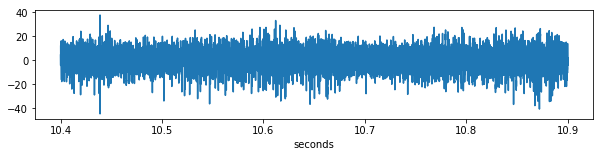

In [13]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10, 2))
plt.plot(elec.t, elec.data[:, 6])
plt.xlabel("seconds")
plt.show()
plt.close(fig)

## 2. Plot raw spikes

The spike times we sort are also saved with times relative to the start of the first session. The time scales of both should be aligned.

First, we load the sorted data... the data I chose was sorted with 2 clusters

The sorted data is in a hierarchical format (clusters of clusters). First, I flatten it out using `flatten()`

In [14]:
from suss.io import read_pickle

sorted_data = read_pickle(
    "../data/birds/BroGre4497M/sites/BroGre4497M_180610_114535/manually_curated/curated-e14.pkl"
)

In [15]:
print(sorted_data)

ClusterDataset with 2 clusters and 168032 waveforms (time=4175.046s)


### Example: plot signal around spikes

Lets say we want to plot the surrounding 5ms around each spike

In [16]:
spikes = sorted_data.flatten()
print(spikes)

SubDataset with 168032 waveforms (time=4739.375s)
  > derived from SpikeDataset with 184233 waveforms (time=4928.292s)


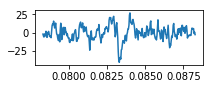

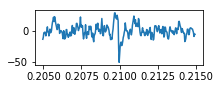

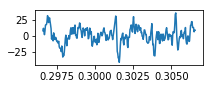

In [19]:
for t_spike in spikes.times[:3]:
    fig = plt.figure(figsize=(3, 1))
    elec = lazy_site.time_slice(t_spike - 0.005, t_spike + 0.005)["filtered"]
    plt.plot(elec.t, elec.data[:, 6])
    plt.show()
    plt.close(fig)
    

### Example: Plot spikes for specific cluster

If I want to only plot the spikes for one of the clusters, I first identify the label of the cluster, and then select only that set of spikes.

In [21]:
print(sorted_data.labels)

[116 115]


In [30]:
spikes_115 = spikes.select(spikes.labels == 115)

<IPython.core.display.Javascript object>


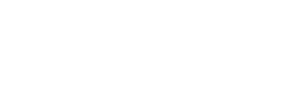

<IPython.core.display.Javascript object>


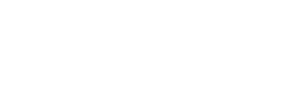

<IPython.core.display.Javascript object>


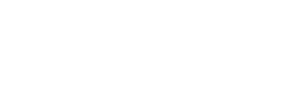

In [31]:
for t_spike in spikes_115.times[:3]:
    fig = plt.figure(figsize=(3, 1))
    elec = lazy_site.time_slice(t_spike - 0.005, t_spike + 0.005, signal="filtered")
    plt.plot(elec.t, elec.data[:, 6])
    plt.show()
    plt.close(fig)
    

<IPython.core.display.Javascript object>


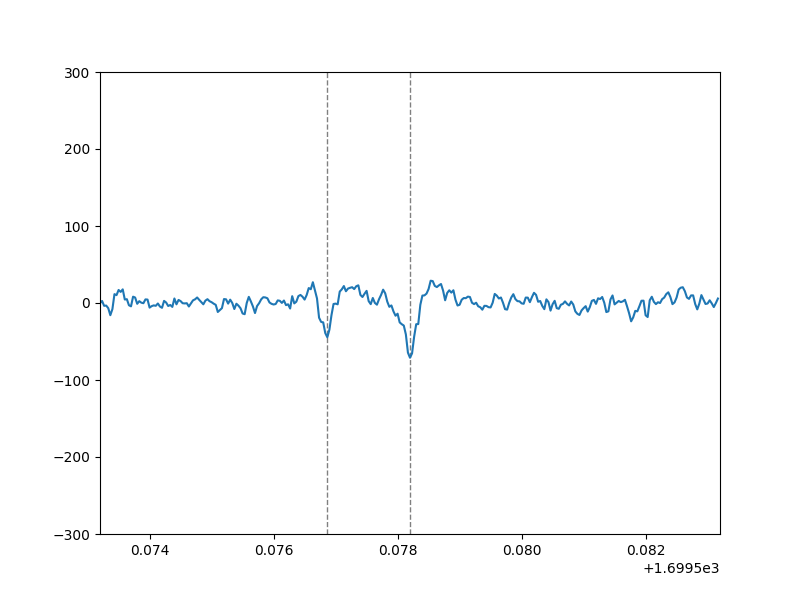

In [32]:
from ipywidgets import interact, widgets, HBox, VBox, Output
%matplotlib notebook

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 6))

yscale_slider = widgets.FloatSlider(
    value=300,
    min=0,
    max=500,
    step=10,
    description='Scale (uV):',
    disabled=False,
    continuous_update=False,
    orientation='vertical',
    readout=True,
    readout_format='.1f',
)

spike_idx_slider = widgets.IntSlider(
    value=0,
    min=0,
    max=len(spikes) - 1,
    step=1,
    description='Spike:',
    disabled=False,
    continuous_update=False,
    orientation='horizontal',
    readout=True,
    readout_format='d'
)

t_width_slider = widgets.FloatSlider(
    value=5,
    min=1,
    max=100,
    step=1,
    description='Time Scale (ms):',
    disabled=False,
    continuous_update=False,
    orientation='horizontal',
    readout=True,
    readout_format='.1f',
)

def update_drawing(spike_idx, ylim, t_width):
    t_width = t_width / 1000.0
    ax.clear()

    spike_time = spikes.times[spike_idx]
    
    elec = lazy_site.time_slice(spike_time - t_width, spike_time + t_width, signal="filtered")

    ax.plot(elec.t, elec.data[:, 6])
    ax.set_ylim(-ylim, ylim)

    ax.vlines(spikes.times[max(spike_idx - 200, 0): spike_idx + 200],
              *ax.get_ylim(), 
              "Gray",
              linestyle="--",
              linewidth=1)

    ax.set_xlim(spike_time - t_width, spike_time + t_width)
    
    fig.canvas.draw()
    
out = widgets.interactive_output(update_drawing, dict(
    spike_idx=spike_idx_slider, 
    ylim=yscale_slider,
    t_width=t_width_slider
))
display(HBox([yscale_slider, out, spike_idx_slider, t_width_slider]))
